##Part a

ODESolver, from "Practice with Boundary Value Problems"

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

class ODESolver(object):
    """
    Superclass for numerical methods solving scalar and vector ODEs
      du/dt = f(u, t)
    Attributes:
    t: array of time values
    u: array of solution values (at time points t)
    k: step number of the most recently computed solution
    f: callable object implementing f(u, t)
    """
    def __init__(self, f):
        if not callable(f):
            raise TypeError('f is %s, not a function' % type(f))
        # For ODE systems, f will often return a list, but
        # arithmetic operations with f in numerical methods
        # require that f is an array. Let self.f be a function
        # that first calls f(u,t) and then ensures that the
        # result is an array of floats.
        self.f = lambda u, t: np.asarray(f(u, t), float)

    def advance(self):
        """Advance solution one time step."""
        raise NotImplementedError

    def set_initial_condition(self, U0):
        if isinstance(U0, (float,int)):
            self.neq = 1
            U0 = float(U0)
        else:
            U0 = np.asarray(U0)
            self.neq = U0.size
        self.U0 = U0

        # Check that f returns correct length:
        try:
            f0 = self.f(self.U0, 1.0)
        except IndexError:
            raise IndexError('Index of u out of bounds in f(u,t) func. Legal indices are %s' % (str(range(self.neq))))
        if f0.size != self.neq:
            raise ValueError('f(u,t) returns %d components, while u has %d components' % (f0.size, self.neq))

    def solve(self, time_points, terminate=None):
        """
        Compute solution u for t values in the list/array
        time_points, as long as terminate(u,t,step_no) is False.
        terminate(u,t,step_no) is a user-given function
        returning True or False. By default, a terminate
        function which always returns False is used.
        """
        if terminate is None:
            terminate = lambda u, t, step_no: False

        if isinstance(time_points, (float,int)):
            raise TypeError('solve: time_points is not a sequence')
        self.t = np.asarray(time_points)
        if self.t.size <= 1:
            raise ValueError('ODESolver.solve requires time_points array with at least 2 time points')

        n = self.t.size
        if self.neq == 1:
            self.u = np.zeros(n)
        else:
            self.u = np.zeros((n,self.neq))

        # Assume that self.t[0] corresponds to self.U0
        self.u[0] = self.U0

        # Time loop
        for k in range(n-1):
            self.k = k
            self.u[k+1] = self.advance()
            if terminate(self.u, self.t, self.k+1):
                break
        return self.u[:k+2], self.t[:k+2]

4th-Order Runge-Kutta, from "Practice with Boundary Value Problems"

In [2]:
class RungeKutta4(ODESolver):
    def advance(self):
        u, f, k, t = self.u, self.f, self.k, self.t
        dt = t[k+1] - t[k]
        dt2 = dt/2.0
        K1 = dt*f(u[k], t[k])
        K2 = dt*f(u[k] + 0.5*K1, t[k] + dt2)
        K3 = dt*f(u[k] + 0.5*K2, t[k] + dt2)
        K4 = dt*f(u[k] + K3, t[k] + dt)
        u_new = u[k] + (1/6.0)*(K1 + 2*K2 + 2*K3 + K4)
        return u_new

Boundary Value Problem Setup, from "Practice with Boundary Value Problems"

In [3]:
# Nondimensional frequency (pick one to test)
varpi = 0.5

# Input the ODE
def f(u, x):
    F, dF = u
    return [dF, -(varpi**2 / x) * F]

# Boundary Conditions
F0 = 0.0
FN = 1


# Set up the domain
domain = [1e-6,1]          # Domain runs from x' = 0 to x' = L (choose L = 100)
N = 1000               # Number of grid points across the domain
x_points = np.linspace(domain[0], domain[1], N)

Specify Solution Vector at a Point, from "Practice with Boundary Value Problems"

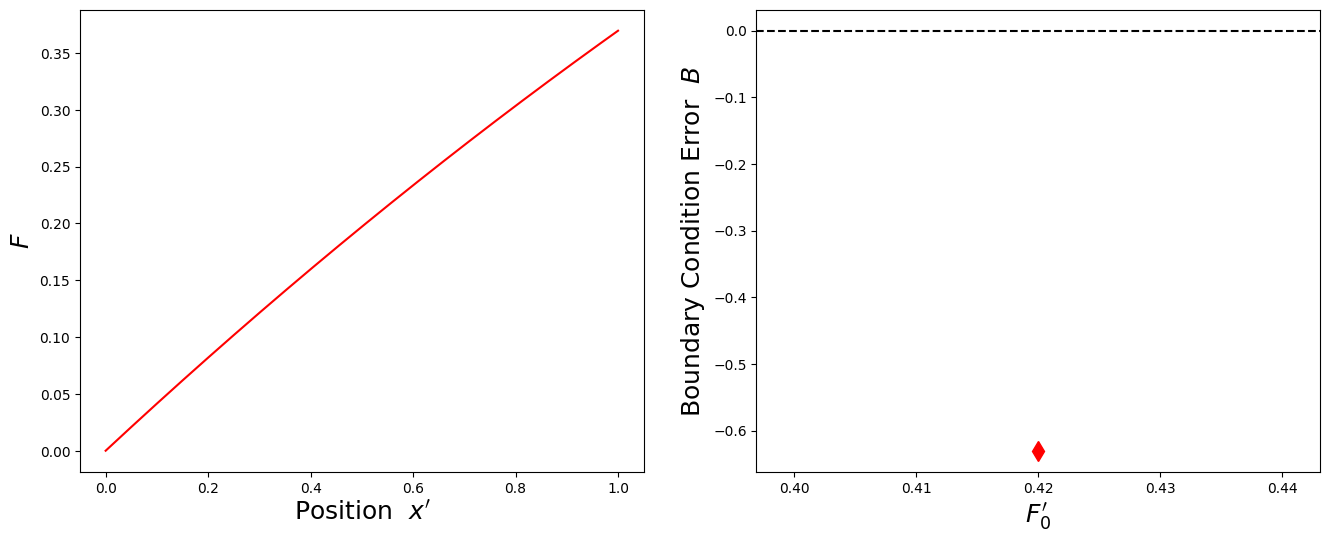

In [4]:
# Set up a single integration

# Initial values
dF0 = 0.42                 # Guess for the derivative at the starting point
F_init = [F0, dF0]         # Initial value for the vector solution

# Perform numerical integration
RK4 = RungeKutta4(f)
RK4.set_initial_condition(F_init)
Fsol, xs = RK4.solve(x_points)    # Fsol[:,0] = F, Fsol[:,1] = dF/dx'

# Plot
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))
ax[0].plot(xs, Fsol[:, 0], color='red')

# Boundary value error at x' = 1
B = Fsol[-1, 0] - FN              # we want B = 0

# Prettify
ax[0].set_xlabel("Position  $x'$", fontsize=18)
ax[0].set_ylabel("$F$", fontsize=18)
ax[1].set_xlabel("$F_0'$", fontsize=18)
ax[1].set_ylabel("Boundary Condition Error  $B$", fontsize=18)
ax[1].plot(dF0, B, color='red', marker='d', markersize=10, linestyle='')
ax[1].axhline(0.0, linestyle='--', color='black')

plt.show()

Bracket, from "Practice with Boundary Value Problems"

slopes: [0.42, 0.6]
B values: [np.float64(-0.6303417157095472), np.float64(-0.4719167367279248)]


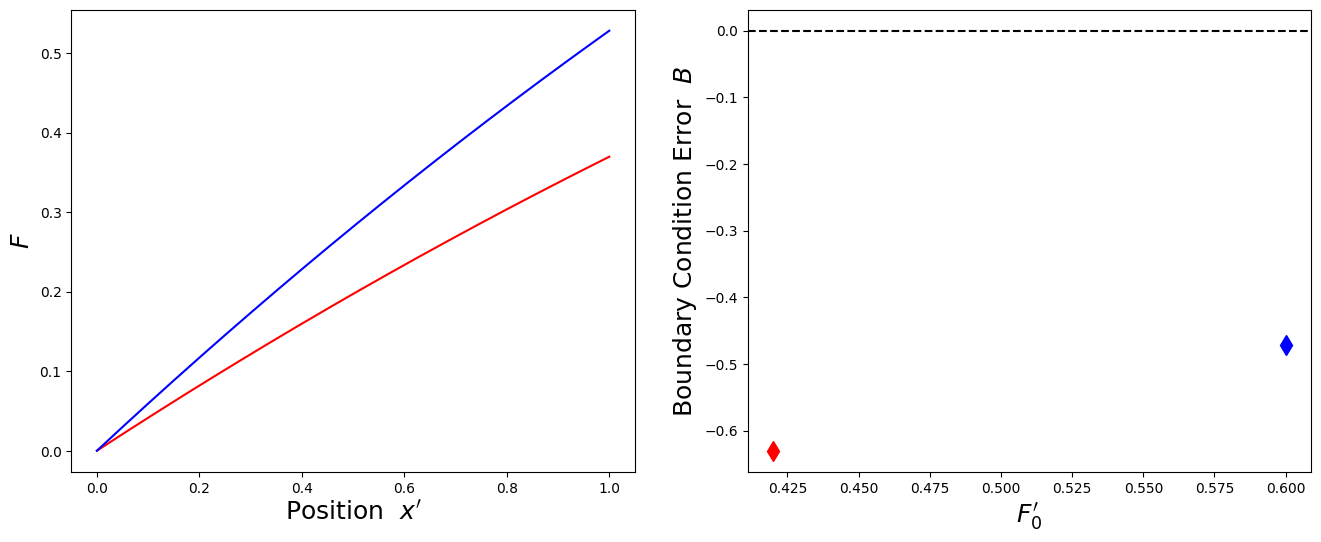

In [5]:
# Perform a second integration

# Keep the first guess, then make a second one
dF_first = dF0           # first guess (0.42)
B_first = B              # its boundary error

dF0 = 0.6            # second guess, chosen near the expected answer
F_init = [F0, dF0]

# Numerically integrate
RK4.set_initial_condition(F_init)
Fsol, xs = RK4.solve(x_points)
bc = Fsol[-1, 0] - FN
ax[0].plot(xs, Fsol[:, 0], color='blue')
ax[1].plot(dF0, bc, color='blue', marker='d', markersize=10, linestyle='')

# Boundary condition errors for both guesses
dF = [dF_first, dF0]
B = [B_first, bc]

print("slopes:", dF)
print("B values:", B)

display(fig)

bracket slopes: [1.1, 1.6]
bracket B values: [np.float64(-0.03184735066786204), np.float64(0.40822203539220037)]


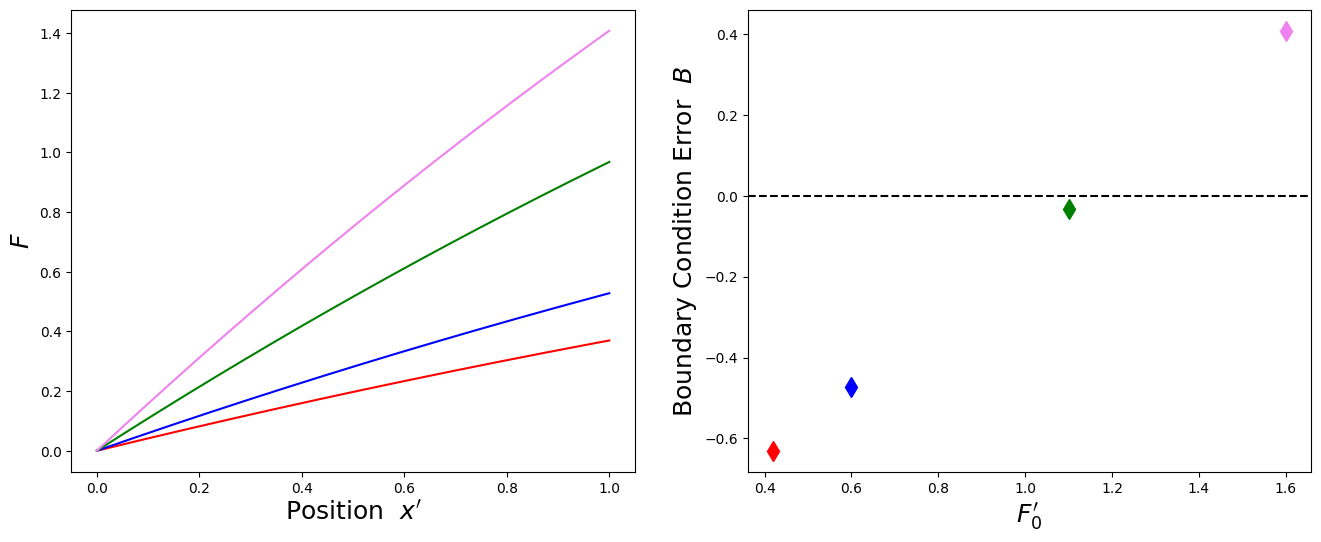

In [6]:
# Find a bracketing pair

# Which direction should we walk
dB = B[1] - B[0]
if (B[0] * dB < 0.0):
    d = 0.5
else:
    d = -0.5

# Search for a bracket if we don't already have one
cols = ['green', 'violet', 'orange', 'cyan', 'darkgreen', 'gold']
icol = -1

doit = True if (B[0] * B[1] > 0.0) else False
while doit:                   # Keep walking until the bracket is found
    dF0 = dF[-1] + d
    F_init = [F0, dF0]
    RK4.set_initial_condition(F_init)
    Fsol, xs = RK4.solve(x_points)
    bc = Fsol[-1, 0] - FN

    icol += 1
    c = cols[icol % len(cols)]
    ax[0].plot(xs, Fsol[:, 0], color=c)
    ax[1].plot(dF0, bc, color=c, marker='d', markersize=10, linestyle='')

    dF = [dF[-1], dF0]
    B = [B[-1], bc]
    doit = True if (B[0] * B[1] > 0.0) else False    # Bracket found?

print("bracket slopes:", dF)
print("bracket B values:", B)
display(fig)

Bisect, from "Practice with Boundary Value Problems"

converged slope: 1.1361852645874024
F(1) = 1.000000703674938


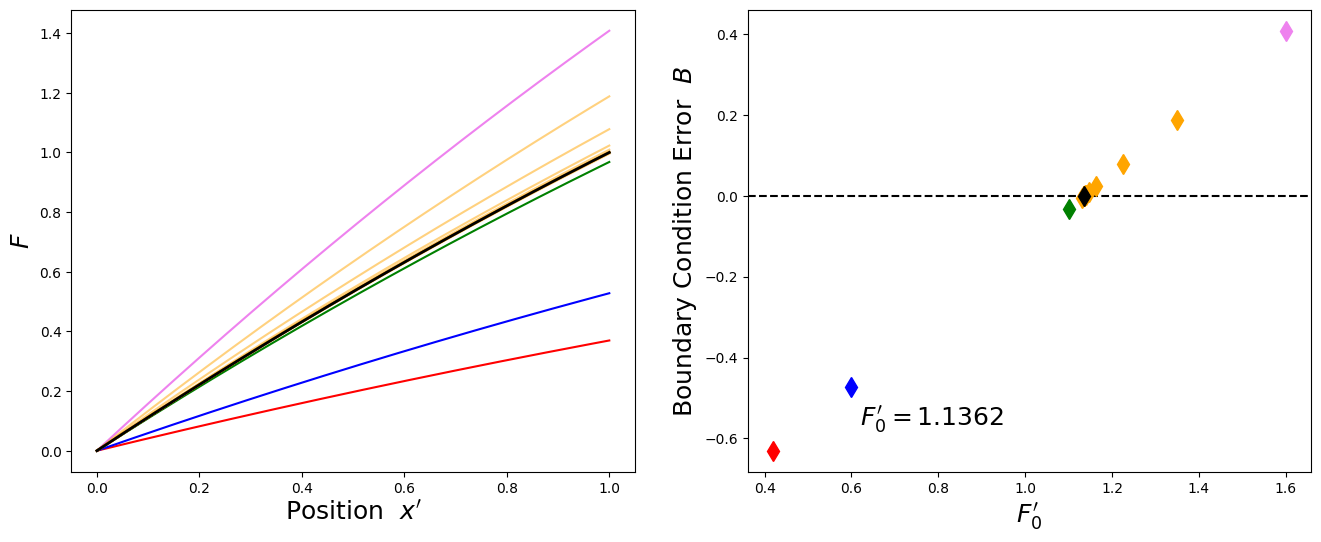

In [7]:
# Bisect the bracket until we get a sufficiently accurate answer

# Input the desired level of accuracy
tol = 1e-6             # desired level of accuracy in the slope

# Keep bisecting until converged = True
converged = True if (np.abs(dF[1] - dF[0]) < tol) else False
icol += 1
while (not converged):
    dF0 = 0.5 * (dF[1] + dF[0])
    F_init = [F0, dF0]
    RK4.set_initial_condition(F_init)
    Fsol, xs = RK4.solve(x_points)
    bc = Fsol[-1, 0] - FN

    c = cols[icol % len(cols)]
    ax[0].plot(xs, Fsol[:, 0], color=c, alpha=0.5)
    ax[1].plot(dF0, bc, color=c, marker='d', markersize=10, linestyle='')

    if (bc * B[0] > 0.0):      # Replace the bracketing guess that has the same sign as the new guess
        dF = [dF0, dF[1]]
        B = [bc, B[1]]
    else:
        dF = [dF[0], dF0]
        B = [B[0], bc]

    converged = True if (np.abs(dF[1] - dF[0]) < tol) else False    # Desired accuracy met?

# Prettify
ax[0].plot(xs, Fsol[:, 0], color='black', linewidth=2)
ax[1].plot(dF0, bc, color='black', marker='d', markersize=10, linestyle='')
ax[1].text(0.2, 0.1, "$F_0' = ${:6.4f}".format(dF[0]),
           fontsize=18, transform=ax[1].transAxes)

print("converged slope:", dF0)
print("F(1) =", Fsol[-1, 0])        # should be 1 to within about tol * (dF/dslope)
display(fig)

##Part b

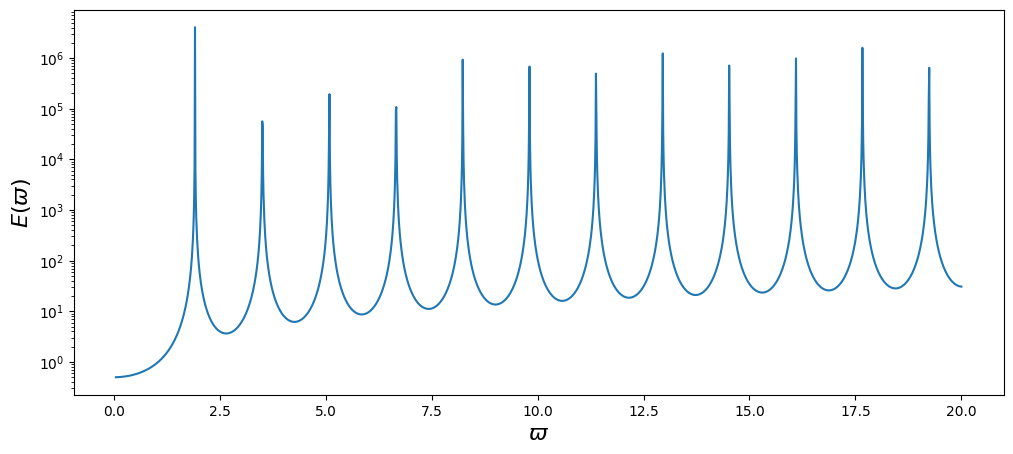

In [ ]:
def energy(varpi_val, eps=1e-6, N=1000):
    def ode(u, x):
        F, dF = u
        return [dF, -(varpi_val**2 / x) * F]
    x = np.geomspace(eps, 1.0, N)
    solver = RungeKutta4(ode)
    solver.set_initial_condition([0.0, 1.0])
    sol, x = solver.solve(x)
    F = sol[:, 0] / sol[-1, 0]         # enforce F(1) = 1; gives the same slope as bisection
                                        # (but more efficient)---provided by Claude
    u = F / x                           # nondimensional velocity
    return 0.5 * np.trapezoid(u**2, x)  # use np.trapz for integration (more stable)

varpi_vals = np.linspace(0.05, 20, 2000)
integrated_KE = np.array([energy(v) for v in varpi_vals])

plt.figure(figsize=(12, 5))
plt.semilogy(varpi_vals, integrated_KE)
plt.xlabel(r"$\varpi$", fontsize=16)
plt.ylabel(r"$E(\varpi)$", fontsize=16)
plt.show()

##Part c

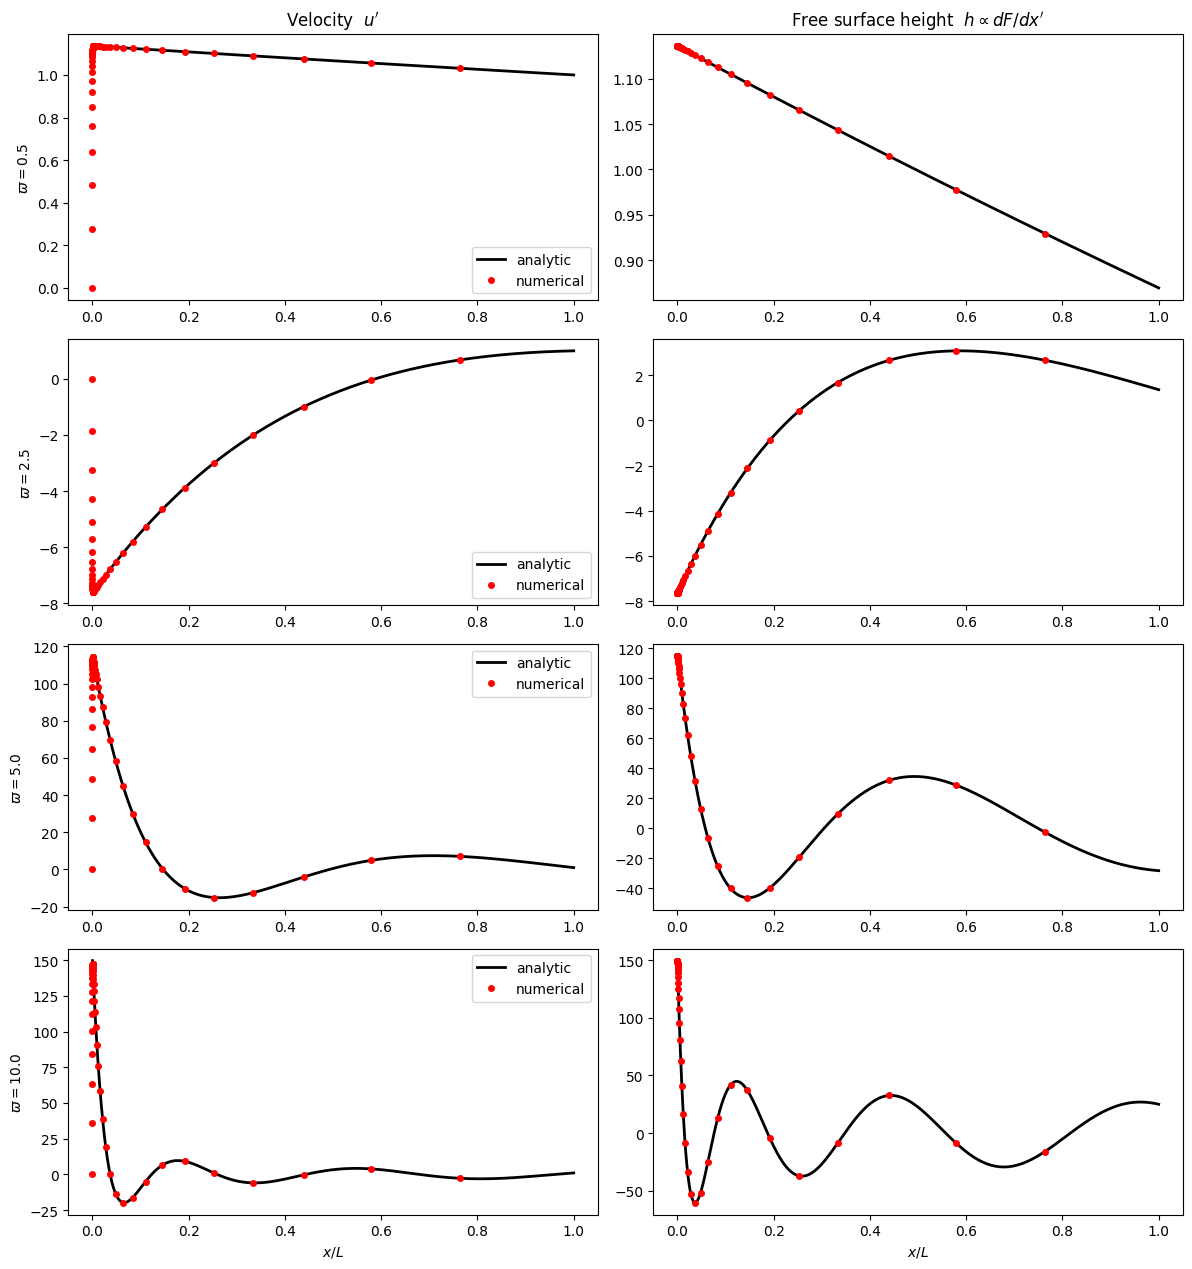

In [17]:
from scipy.special import jv

def solve_F(varpi_val, eps=1e-6, N=2000): #make epsilon bigger
    def ode(u, x):
        F, dF = u
        return [dF, -(varpi_val**2 / x) * F]
    x = np.geomspace(eps, 1.0, N)
    solver = RungeKutta4(ode)
    solver.set_initial_condition([0.0, 1.0])
    sol, x = solver.solve(x)
    F  = sol[:, 0] / sol[-1, 0]      # enforce F(1) = 1
    dF = sol[:, 1] / sol[-1, 0]      # dF/dx'
    return x, F, dF

varpi_list = [0.5, 2.5, 5.0, 10.0]
fig, axes = plt.subplots(len(varpi_list), 2, figsize=(12, 3.2*len(varpi_list)))

for row, v in enumerate(varpi_list):
    x, F, dF = solve_F(v)
    u_num = F / x                    # velocity
    h_num = dF                       # surface height (shape)

    z = 2*v*np.sqrt(x)
    u_ana = jv(1, z) / (np.sqrt(x) * jv(1, 2*v))
    h_ana = v * jv(0, z) / jv(1, 2*v)

    axes[row, 0].plot(x, u_ana, 'k-', lw=2, label='analytic')
    axes[row, 0].plot(x[::40], u_num[::40], 'ro', ms=4, label='numerical')
    axes[row, 1].plot(x, h_ana, 'k-', lw=2)
    axes[row, 1].plot(x[::40], h_num[::40], 'ro', ms=4)

    axes[row, 0].set_ylabel(rf"$\varpi={v}$")
    axes[row, 0].legend()

axes[0, 0].set_title("Velocity  $u'$")
axes[0, 1].set_title(r"Free surface height  $h \propto dF/dx'$")
axes[-1, 0].set_xlabel("$x/L$"); axes[-1, 1].set_xlabel("$x/L$")
plt.tight_layout(); plt.show()

##Part d

In [40]:
#Define new shape for seabed

def h(x):
  g = lambda x: np.sin(x)
  return g(x) / g(1.0)           # forces boundary condition automatically


# Nondimensional frequency (pick one to test)
varpi = 2.5

# Input the ODE
def f(u, x):
    F, dF = u
    return [dF, -(varpi**2 / h(x)) * F]

# Boundary Conditions
F0 = 0.0
FN = 1


# Set up the domain
domain = [1e-6,1]          # Domain runs from x' = 0 to x' = L (choose L = 100)
N = 1000               # Number of grid points across the domain
x_points = np.linspace(domain[0], domain[1], N)

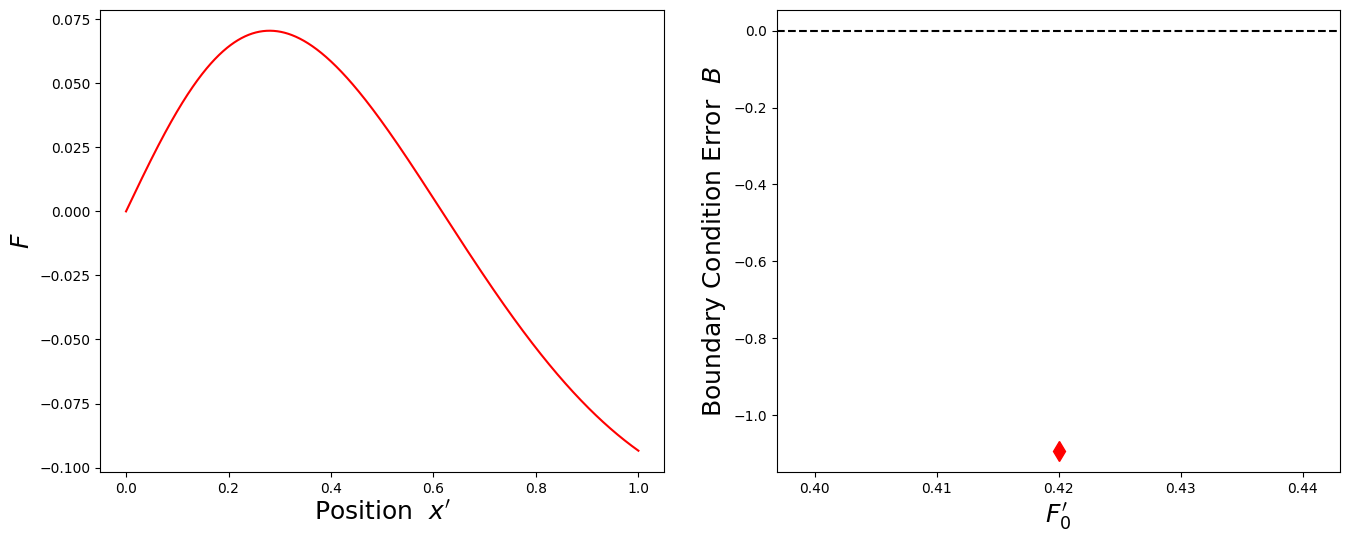

In [41]:
# Set up a single integration

# Initial values
dF0 = 0.42                 # Guess for the derivative at the starting point
F_init = [F0, dF0]         # Initial value for the vector solution

# Perform numerical integration
RK4 = RungeKutta4(f)
RK4.set_initial_condition(F_init)
Fsol, xs = RK4.solve(x_points)    # Fsol[:,0] = F, Fsol[:,1] = dF/dx'

# Plot
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))
ax[0].plot(xs, Fsol[:, 0], color='red')

# Boundary value error at x' = 1
B = Fsol[-1, 0] - FN              # we want B = 0

# Prettify
ax[0].set_xlabel("Position  $x'$", fontsize=18)
ax[0].set_ylabel("$F$", fontsize=18)
ax[1].set_xlabel("$F_0'$", fontsize=18)
ax[1].set_ylabel("Boundary Condition Error  $B$", fontsize=18)
ax[1].plot(dF0, B, color='red', marker='d', markersize=10, linestyle='')
ax[1].axhline(0.0, linestyle='--', color='black')

plt.show()

slopes: [0.42, 0.6]
B values: [np.float64(-1.0934161705776035), np.float64(-1.1334516722537191)]


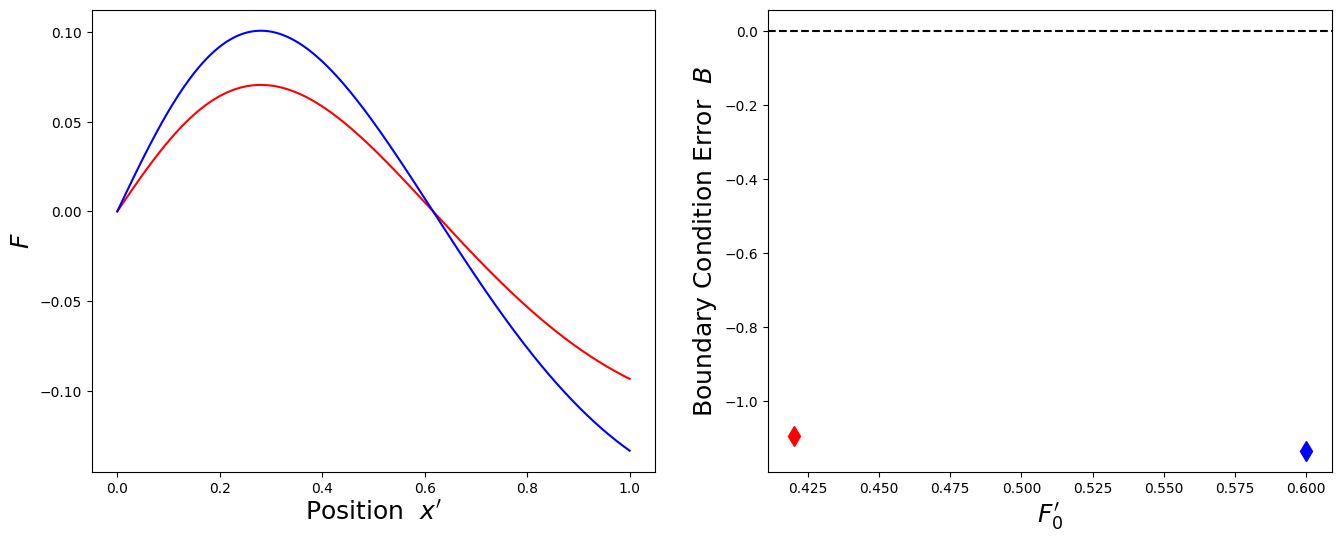

In [42]:
# Perform a second integration

# Keep the first guess, then make a second one
dF_first = dF0           # first guess (0.42)
B_first = B              # its boundary error

dF0 = 0.6            # second guess, chosen near the expected answer
F_init = [F0, dF0]

# Numerically integrate
RK4.set_initial_condition(F_init)
Fsol, xs = RK4.solve(x_points)
bc = Fsol[-1, 0] - FN
ax[0].plot(xs, Fsol[:, 0], color='blue')
ax[1].plot(dF0, bc, color='blue', marker='d', markersize=10, linestyle='')

# Boundary condition errors for both guesses
dF = [dF_first, dF0]
B = [B_first, bc]

print("slopes:", dF)
print("B values:", B)

display(fig)

bracket slopes: [-4.4, -4.9]
bracket B values: [np.float64(-0.02135440347272699), np.float64(0.08985532340537539)]


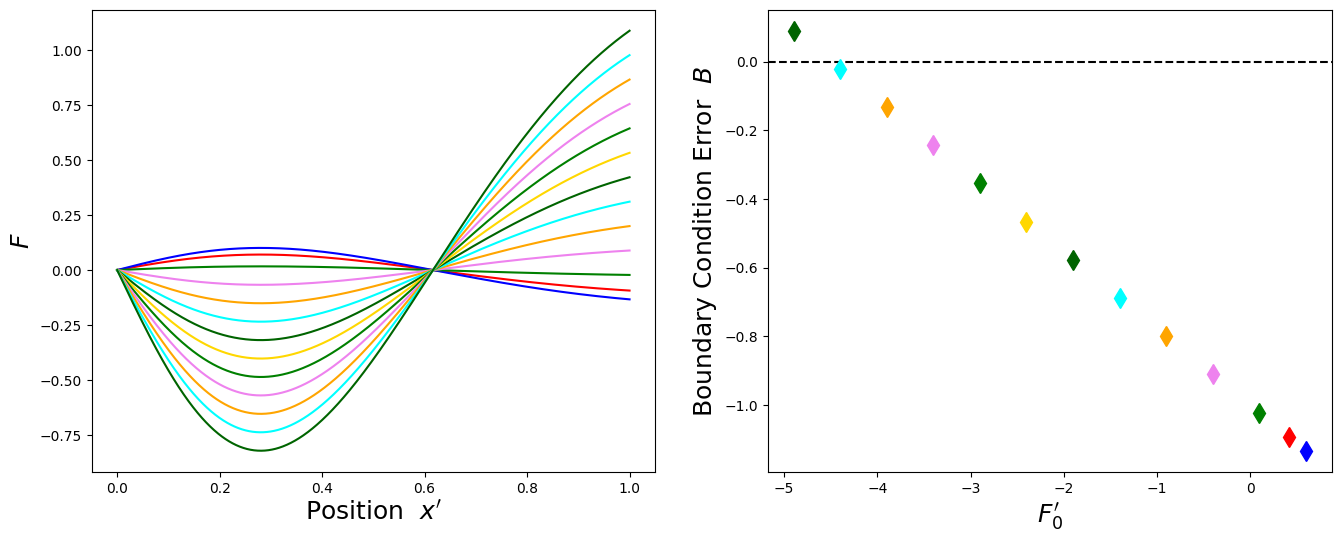

In [43]:
# Find a bracketing pair

# Which direction should we walk
dB = B[1] - B[0]
if (B[0] * dB < 0.0):
    d = 0.5
else:
    d = -0.5

# Search for a bracket if we don't already have one
cols = ['green', 'violet', 'orange', 'cyan', 'darkgreen', 'gold']
icol = -1

doit = True if (B[0] * B[1] > 0.0) else False
while doit:                   # Keep walking until the bracket is found
    dF0 = dF[-1] + d
    F_init = [F0, dF0]
    RK4.set_initial_condition(F_init)
    Fsol, xs = RK4.solve(x_points)
    bc = Fsol[-1, 0] - FN

    icol += 1
    c = cols[icol % len(cols)]
    ax[0].plot(xs, Fsol[:, 0], color=c)
    ax[1].plot(dF0, bc, color=c, marker='d', markersize=10, linestyle='')

    dF = [dF[-1], dF0]
    B = [B[-1], bc]
    doit = True if (B[0] * B[1] > 0.0) else False    # Bracket found?

print("bracket slopes:", dF)
print("bracket B values:", B)
display(fig)

converged slope: -4.496009254455567
F(1) = 0.9999999224588196


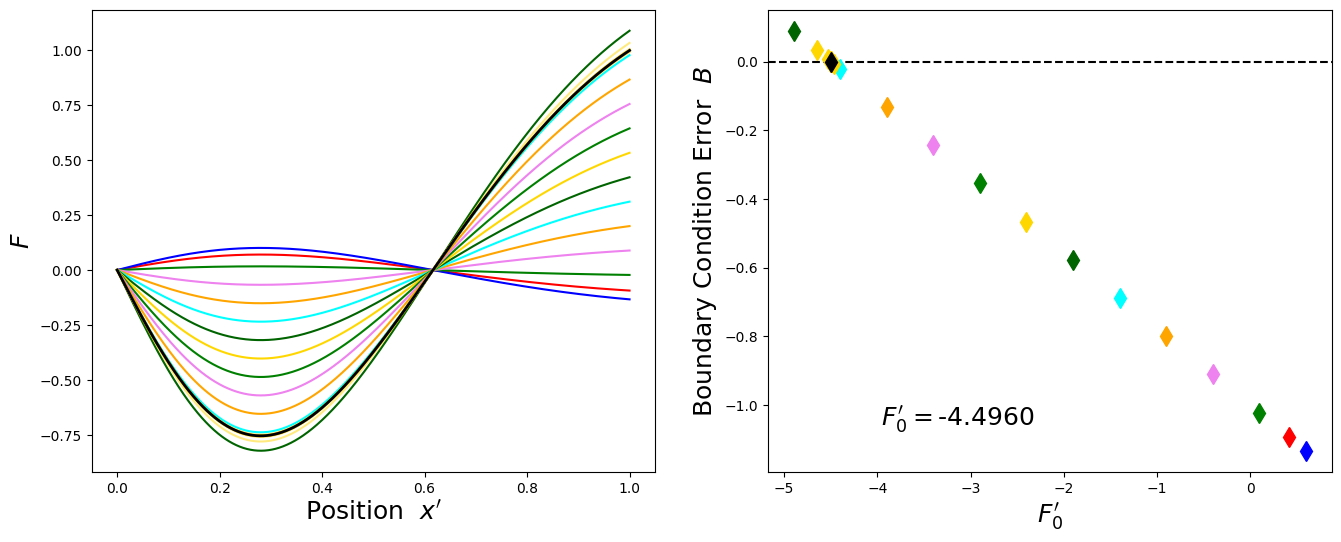

In [44]:
# Bisect the bracket until we get a sufficiently accurate answer

# Input the desired level of accuracy
tol = 1e-6             # desired level of accuracy in the slope

# Keep bisecting until converged = True
converged = True if (np.abs(dF[1] - dF[0]) < tol) else False
icol += 1
while (not converged):
    dF0 = 0.5 * (dF[1] + dF[0])
    F_init = [F0, dF0]
    RK4.set_initial_condition(F_init)
    Fsol, xs = RK4.solve(x_points)
    bc = Fsol[-1, 0] - FN

    c = cols[icol % len(cols)]
    ax[0].plot(xs, Fsol[:, 0], color=c, alpha=0.5)
    ax[1].plot(dF0, bc, color=c, marker='d', markersize=10, linestyle='')

    if (bc * B[0] > 0.0):      # Replace the bracketing guess that has the same sign as the new guess
        dF = [dF0, dF[1]]
        B = [bc, B[1]]
    else:
        dF = [dF[0], dF0]
        B = [B[0], bc]

    converged = True if (np.abs(dF[1] - dF[0]) < tol) else False    # Desired accuracy met?

# Prettify
ax[0].plot(xs, Fsol[:, 0], color='black', linewidth=2)
ax[1].plot(dF0, bc, color='black', marker='d', markersize=10, linestyle='')
ax[1].text(0.2, 0.1, "$F_0' = ${:6.4f}".format(dF[0]),
           fontsize=18, transform=ax[1].transAxes)

print("converged slope:", dF0)
print("F(1) =", Fsol[-1, 0])        # should be 1 to within about tol * (dF/dslope)
display(fig)

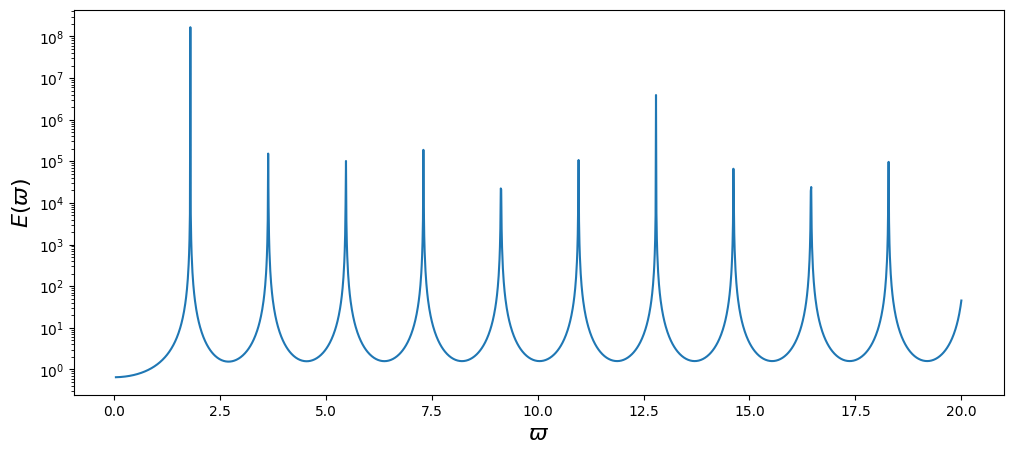

In [45]:
def energy(varpi_val, eps=1e-6, N=1000):
    def ode(u, x):
        F, dF = u
        return [dF, -(varpi_val**2 / h(x)) * F]
    x = np.geomspace(eps, 1.0, N)
    solver = RungeKutta4(ode)
    solver.set_initial_condition([0.0, 1.0])
    sol, x = solver.solve(x)
    F = sol[:, 0] / sol[-1, 0]         # enforce F(1) = 1; gives the same slope as bisection
                                        # (but more efficient)---provided by Claude
    u = F / h(x)                           # nondimensional velocity
    return 0.5 * np.trapezoid(u**2, x)  # use np.trapz for integration (more stable)

varpi_vals = np.linspace(0.05, 20, 2000)
integrated_KE = np.array([energy(v) for v in varpi_vals])

plt.figure(figsize=(12, 5))
plt.semilogy(varpi_vals, integrated_KE)
plt.xlabel(r"$\varpi$", fontsize=16)
plt.ylabel(r"$E(\varpi)$", fontsize=16)
plt.show()

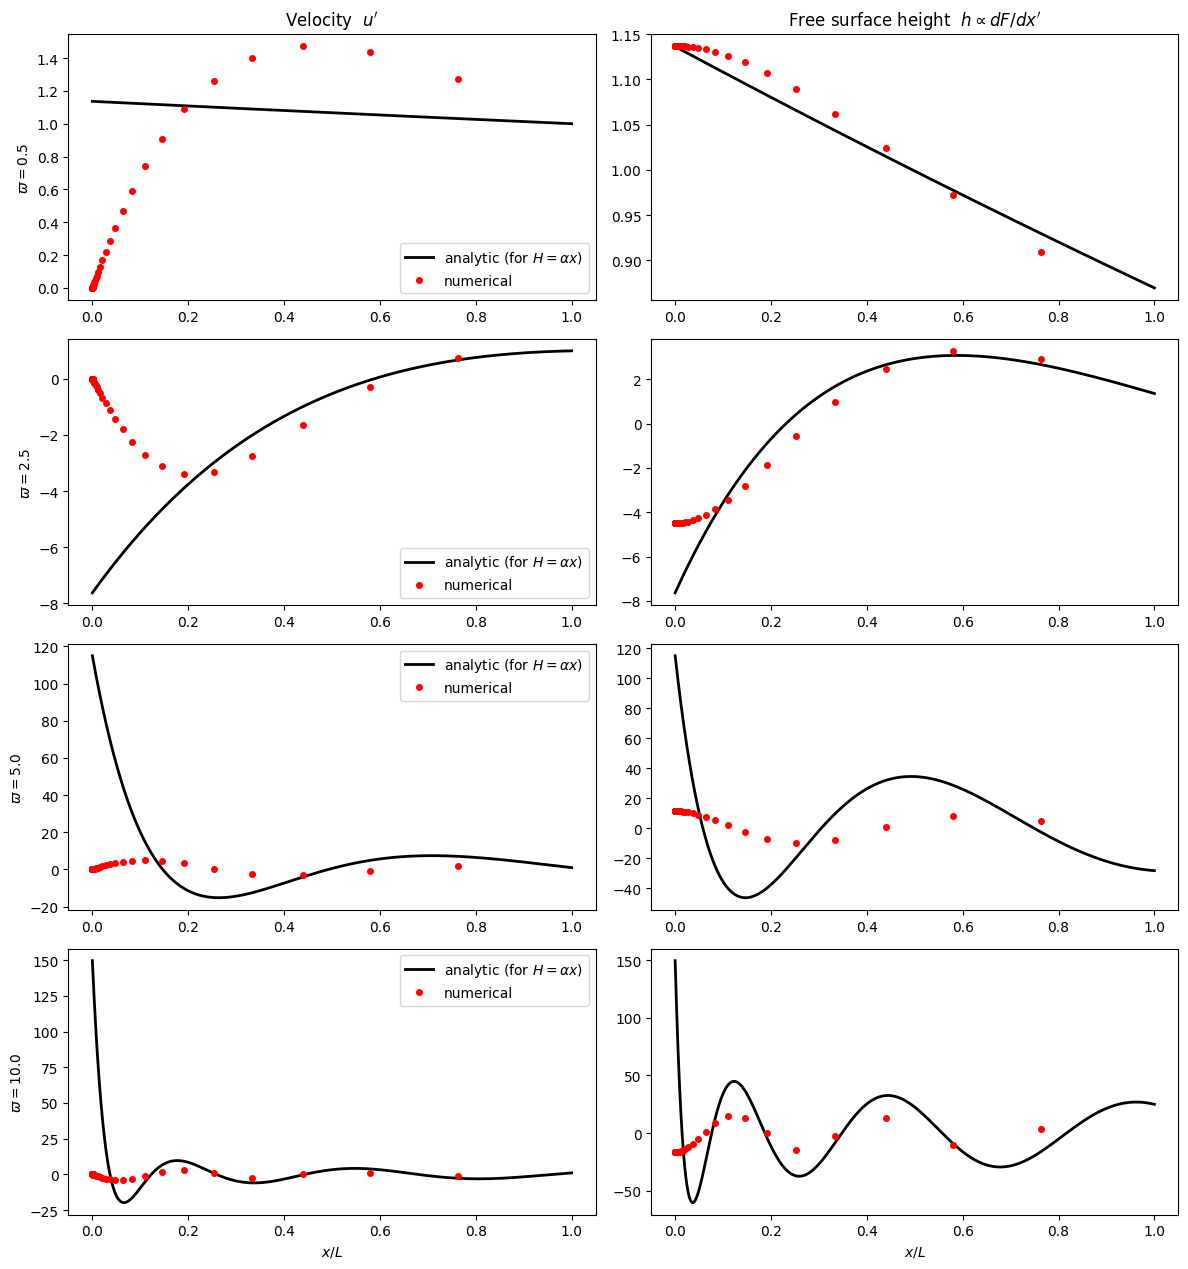

In [46]:
from scipy.special import jv

def solve_F(varpi_val, eps=1e-6, N=2000): #make epsilon bigger
    def ode(u, x):
        F, dF = u
        return [dF, -(varpi_val**2 / h(x)) * F]
    x = np.geomspace(eps, 1.0, N)
    solver = RungeKutta4(ode)
    solver.set_initial_condition([0.0, 1.0])
    sol, x = solver.solve(x)
    F  = sol[:, 0] / sol[-1, 0]      # enforce F(1) = 1
    dF = sol[:, 1] / sol[-1, 0]      # dF/dx'
    return x, F, dF

varpi_list = [0.5, 2.5, 5.0, 10.0]
fig, axes = plt.subplots(len(varpi_list), 2, figsize=(12, 3.2*len(varpi_list)))

for row, v in enumerate(varpi_list):
    x, F, dF = solve_F(v)
    u_num = F / h(x)                    # velocity
    h_num = dF                       # surface height (shape)

    z = 2*v*np.sqrt(x)
    u_ana = jv(1, z) / (np.sqrt(x) * jv(1, 2*v))
    h_ana = v * jv(0, z) / jv(1, 2*v)

    axes[row, 0].plot(x, u_ana, 'k-', lw=2, label=fr'analytic (for $H=\alpha x$)')
    axes[row, 0].plot(x[::40], u_num[::40], 'ro', ms=4, label='numerical')
    axes[row, 1].plot(x, h_ana, 'k-', lw=2)
    axes[row, 1].plot(x[::40], h_num[::40], 'ro', ms=4)

    axes[row, 0].set_ylabel(rf"$\varpi={v}$")
    axes[row, 0].legend()

axes[0, 0].set_title("Velocity  $u'$")
axes[0, 1].set_title(r"Free surface height  $h \propto dF/dx'$")
axes[-1, 0].set_xlabel("$x/L$"); axes[-1, 1].set_xlabel("$x/L$")
plt.tight_layout(); plt.show()